# Bitácora del avance: dataset sintético y normalización geométrica
**Trabajo Final de Inteligencia Artificial I · 15 de octubre de 2026**

**Proyecto:** Sistema de reconocimiento de huellas dactilares controlado por reconocimiento de voz.

Este avance documenta la construcción de un conjunto de huellas **sintéticas** y de una función reutilizable para preparar las imágenes antes de compararlas. Corresponde a la etapa de huellas del proyecto; no incluye todavía extracción de características, K-means, clasificación de comandos de voz con K-NN ni evaluación del agente integrado.

La ejecución publicada procesó 220 muestras. Las celdas de verificación incluidas conservan sus resultados y gráficos y permiten repetir los controles sobre los archivos del repositorio.

**Reproducción de la verificación:** abrir este notebook desde la raíz del repositorio o desde `notebooks/`, seleccionar el intérprete de `.venv` y ejecutar las celdas. Se requiere `ipykernel` además de las dependencias de `requirements.txt`. Las celdas solo leen archivos: no generan muestras ni modifican particiones o resultados.


## 1. Qué se buscó resolver

Antes de reconocer una huella necesitamos imágenes con variaciones de captura y una forma común de representarlas. El trabajo se separó en dos etapas:

1. **Generación:** partir de patrones sintéticos distintos y producir capturas con deformaciones locales, movimiento, variación de contraste, ruido y contacto parcial.
2. **Normalización geométrica:** localizar la región de la huella, centrarla y orientar su eje principal en un lienzo común.

Una **identidad** representa un dedo sintético; una **muestra** es una captura derivada de ese dedo. Rotar una muestra no crea una identidad nueva. En este proyecto `original` significa imagen generada antes de la normalización; no significa una huella real ni una nueva base independiente.

## 2. Bases sintéticas e identidades

Anguli proporcionó los patrones base. Se conservaron los PNG, `Anguli.conf`, metadatos y semillas para registrar su procedencia. La ventana About disponible no identifica una versión numérica de Anguli; por ese motivo no se registra una versión supuesta.

| Identidad | Rol | Carpeta de base | Semilla |
|---|---|---|---:|
| A01 | Autorizado | `piloto_01` | 101 |
| A02 | Autorizado | `piloto_02` | 202 |
| A03 | Autorizado | `autorizado_03` | 303 |
| I01 | Intruso de validación | `intruso_val_01` | 404 |
| I02 | Intruso de validación | `intruso_val_02` | 505 |
| I03 | Intruso de prueba | `intruso_test_01` | 606 |
| I04 | Intruso de prueba | `intruso_test_02` | 707 |

`piloto_01_repeticion` documenta una repetición con la misma semilla: **no es una octava identidad**. Las impresiones generadas por Anguli se conservan como procedencia; el conjunto de trabajo se deriva de las bases indicadas por `config/conjunto_v1.json`.

La etiqueta autorizado/intruso representa el escenario de evaluación del proyecto. Las identidades intrusas de validación son distintas de las de prueba.

## 3. Construcción progresiva del dataset

| Paso | Incorporación | Total acumulado |
|---|---|---:|
| Piloto | 8 variantes para comprobar deformaciones; fuera del conjunto final | — |
| Conjunto inicial | 160 capturas: autorizados e intrusos | 160 |
| Ampliación de entrenamiento | 10 capturas adicionales por autorizado | 190 |
| Rotaciones de entrenamiento | Otras 10 por autorizado | 220 |

Las deformaciones locales usan campos suaves de desplazamiento: distintos sectores de la imagen se mueven de manera diferente. Esto permite variaciones no rígidas; no se limita el aumento de datos a una traslación o rotación global. Se registran parámetros y controles del jacobiano de las transformaciones para controlar deformaciones extremas.

La primera ampliación incluye mayor deformación, posición variable, contraste reducido, menor nitidez y contacto parcial. La segunda utiliza los ángulos **−90, −60, −45, −30, −15, 15, 30, 45, 60 y 90 grados** por autorizado, además de variaciones leves de captura. Estos ángulos definen un escenario sintético de ensayo; no son una especificación universal de un sensor.

Las imágenes iniciales y la primera ampliación tienen 275 × 400 píxeles. Para los giros amplios se utilizó un lienzo de 512 × 512 sin estirar el patrón, evitando el recorte que produciría girar dentro del rectángulo original.

## 4. Particiones y límites de la evaluación

| Grupo | Entrenamiento | Validación | Prueba | Total |
|---|---:|---:|---:|---:|
| A01 | 40 | 10 | 10 | 60 |
| A02 | 40 | 10 | 10 | 60 |
| A03 | 40 | 10 | 10 | 60 |
| I01 e I02 | 0 | 20 | 0 | 20 |
| I03 e I04 | 0 | 0 | 20 | 20 |
| **Total** | **120** | **50** | **50** | **220** |

Para cada autorizado: M01–M20 son entrenamiento inicial; M21–M30 validación; M31–M40 prueba; M41–M50 primera ampliación y M51–M60 rotaciones, ambas de entrenamiento.

Entrenamiento sirve para ajustar el futuro modelo; validación para decisiones y parámetros; prueba para la evaluación final. Diez muestras de prueba tienen la marca `reserva_demo`: están incluidas en las 50 de prueba, no se suman al total. Debe respetarse esa reserva cuando se defina el protocolo final.

Las capturas de un autorizado comparten una base entre particiones: esto representa nuevas capturas de dedos conocidos, **no generalización a identidades nuevas ni a huellas reales**. La diversidad sigue estando limitada a siete bases sintéticas. Las particiones se conservan durante las etapas posteriores y todas las representaciones de una misma muestra permanecen juntas.

## 5. Trazabilidad y catálogos

Se guardan semillas, parámetros, rutas, particiones, identidad y hashes SHA-256. La semilla permite repetir la generación bajo las mismas condiciones; el hash permite comprobar si los bytes de un archivo cambiaron. También importan la base, el código y las versiones de las dependencias: guardar solo una semilla no garantiza reproducibilidad entre entornos diferentes.

| Catálogo | Contenido |
|---|---|
| `datos/metadatos.csv` | 160 muestras iniciales |
| `datos/metadatos_ampliacion_train_v1.csv` | Solo las 30 de la primera ampliación |
| `datos/metadatos_con_ampliacion_train_v1.csv` | Acumulado de 190 |
| `datos/metadatos_rotaciones_train_v1.csv` | Solo las 30 rotadas |
| `datos/metadatos_con_rotaciones_train_v1.csv` | **220 originales: entrada de la normalización** |
| `datos/procesados/normalizacion_final_v1/catalogo_normalizado.csv` | **220 filas con las rutas de las representaciones finales** |

Los catálogos acumulados son versiones sucesivas; concatenarlos duplicaría muestras. En el catálogo final se conservan columnas antiguas por trazabilidad. Para las próximas etapas usar `normalizada` y `alternativa_180`, no la columna heredada `procesado`. Esta última conserva 160 rutas a resultados preliminares que no se incluyen en la publicación actual; su ausencia no afecta la lectura de las representaciones finales.

## 6. Qué hace la normalización

La primera etapa probó la detección de la región y el centrado. La versión final utiliza el siguiente procedimiento para **cada imagen**, tanto en lote como en futuras entradas:

1. Convertir a gris y verificar que haya contraste suficiente.
2. Suavizar una copia para detectar la región; cerrar pequeños huecos, conservar la región principal y añadir un margen.
3. Colocar esa región en un lienzo blanco, manteniendo la escala en píxeles.
4. Estimar el eje principal con la covarianza de las coordenadas de la máscara rellena.
5. Girar para colocar ese eje vertical y volver a centrar en 512 × 512.
6. Guardar representaciones, máscara e información de control.

La relación entre autovalores debe ser al menos 1,2. Si el contorno es casi circular, el eje no es suficientemente claro: se conserva la orientación y se emite un aviso. La rotación usa interpolación lineal; puede suavizar algo las crestas.

La función no consulta identidad, semilla ni ángulo conocido de generación para decidir el giro. La configuración se mantiene fija para entrenamiento, validación y prueba. Las comparaciones visuales seleccionadas son de desarrollo.

Esta versión normaliza la **geometría**. No iguala el contraste entre capturas, no corrige deformaciones elásticas, no reconstruye áreas ausentes ni calcula minucias. Tampoco normaliza resolución física en DPI. Los procesados preliminares de `conjunto_v1` quedan como antecedente; la versión final parte de los originales.

## 7. Por qué guardamos tres PNG por muestra

Ejemplo: `A01_M01`.

| Archivo | Qué contiene | Para qué sirve |
|---|---|---|
| `A01_M01.png` | Huella centrada y con eje vertical | Representación principal |
| `A01_M01_180.png` | Giro exacto de 180° de la anterior | Considerar la dirección opuesta al comparar |
| `A01_M01_mascara.png` | Blanco dentro de la región; negro fuera | Auditar la segmentación y delimitar dónde analizar |

El eje geométrico no tiene una flecha que indique la punta del dedo: dos direcciones separadas por 180° describen el mismo eje. Por eso **vertical no implica una orientación anatómica única**. El método de comparación futuro deberá contemplar ambas orientaciones o ser invariante a ese giro.

La máscara no muestra crestas y no es una muestra de entrenamiento. La alternativa tampoco es una nueva observación independiente.

**220 muestras × 3 PNG = 660 archivos derivados**, además de los 220 originales y las imágenes de comparación. El catálogo mantiene 220 filas. La carga de datos se realiza a partir del catálogo, distinguiendo las representaciones y las máscaras; no mediante una lista indiscriminada de todos los PNG.

## 8. Organización del repositorio

| Carpeta | Contenido y función |
|---|---|
| `src/` | Funciones y programas de generación, ampliación y normalización |
| `config/` | Configuraciones JSON de las etapas |
| `datos/bases/` | Patrones y archivos de procedencia de Anguli |
| `datos/originales/conjunto_v1/` | 160 capturas iniciales |
| `datos/originales/ampliacion_train_v1/` | 30 capturas de entrenamiento adicionales |
| `datos/originales/rotaciones_train_v1/` | 30 capturas de entrenamiento con giros amplios |
| `datos/procesados/conjunto_v1/` | Antecedente local no publicado; no es la entrada final del reconocedor |
| `datos/procesados/normalizacion_final_v1/` | Representaciones finales, máscaras, catálogo y auditoría |
| `resultados/` | Salidas de ensayos intermedios locales; no incluidas en esta publicación |
| `notebooks/` | Bitácoras, explicación y exploración reproducible |
| `documentos/` | Decisiones, instrucciones y documentación técnica |
| `.venv/` | Entorno local; no se sube a GitHub |

Dentro de la salida final se conservan las carpetas `entrenamiento`, `validacion` y `prueba`, cada una organizada por identidad. `resumen.json` contiene conteos; `detalle.json` los controles por muestra; `config_efectiva.json` los parámetros; `entorno.json` versiones y hashes; `comparaciones_desarrollo/` los paneles de inspección.

## 9. Responsabilidad de cada script y configuración

| Archivo en `src/` | Responsabilidad |
|---|---|
| `piloto_deformaciones.py` | Ensayo inicial de deformaciones locales y utilidades que utiliza la generación |
| `generar_conjunto.py` | Construye las 160 muestras iniciales y sus metadatos |
| `ampliar_entrenamiento.py` | Añade 30 capturas y genera el acumulado de 190 |
| `ampliar_rotaciones.py` | Añade 30 capturas rotadas y genera el acumulado de 220 |
| `normalizacion.py` | Función de la primera etapa: región y centrado |
| `normalizar_dataset.py` | Ensayo de la primera etapa sobre desarrollo |
| `roi_normalizacion_v1.py` | Copia versionada de la función de región y centrado usada por la versión final |
| `normalizacion_final.py` | Función reutilizable: región, giro, centrado y alternativa de 180° |
| `normalizar_todas.py` | Lee el catálogo, aplica la función final, guarda PNG, catálogo y controles |

| Archivo en `config/` | Uso |
|---|---|
| `piloto_deformaciones.json` | Parámetros del piloto |
| `conjunto_v1.json` | Bases, semillas y perfiles del conjunto inicial |
| `ampliacion_train_v1.json` | Perfiles de la primera ampliación |
| `normalizacion_etapa1.json` | Parámetros del ensayo de región y centrado |
| `roi_normalizacion_v1.json` | Parámetros de región utilizados en el lote final |

Los ángulos de la ampliación rotada están definidos en `ampliar_rotaciones.py`; no existe una configuración JSON independiente para esa ampliación. El umbral de relación de autovalores 1,2 está en el módulo final y registrado en la configuración efectiva. Conservar los módulos antiguos permite rastrear el avance y mantiene las dependencias de los generadores.

## 10. Verificación de la ejecución publicada

Las siguientes celdas leen los catálogos y las imágenes del repositorio. `NOMBRE_SALIDA` identifica la ejecución que se desea verificar; su valor predeterminado corresponde al lote publicado. La raíz se localiza desde la carpeta del notebook o desde la raíz del repositorio. No se requiere pandas.

Las verificaciones de integridad se aplican al conjunto completo. Los ejemplos visuales se limitan a entrenamiento y validación; estos controles no seleccionan parámetros con los datos de prueba.


In [1]:
from pathlib import Path
from collections import Counter
import csv, json, hashlib
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

NOMBRE_SALIDA = "normalizacion_final_v1"
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "datos/metadatos_con_rotaciones_train_v1.csv").is_file()), None)
if RAIZ is None:
    raise FileNotFoundError("Abrí el notebook dentro de Trabajo-Final-IA1.")
SALIDA = RAIZ / "datos/procesados" / NOMBRE_SALIDA

def leer_csv(path):
    with path.open(encoding="utf-8-sig", newline="") as f:
        return list(csv.DictReader(f))

originales = leer_csv(RAIZ / "datos/metadatos_con_rotaciones_train_v1.csv")
filas = leer_csv(SALIDA / "catalogo_normalizado.csv")
resumen = json.loads((SALIDA / "resumen.json").read_text(encoding="utf-8"))
print(json.dumps(resumen, indent=2, ensure_ascii=False))

{
  "solicitadas": 220,
  "correctas": 218,
  "revisar": 2,
  "errores": 0,
  "particiones": {
    "entrenamiento": 120,
    "validacion": 50,
    "prueba": 50
  },
  "ambiguedad_180": true,
  "contraste_modificado": false
}


In [2]:
assert len(originales) == len(filas) == 220
assert len({r["muestra"] for r in filas}) == 220
esperado = {"entrenamiento": 120, "validacion": 50, "prueba": 50}
assert dict(Counter(r["particion"] for r in filas)) == esperado
assert resumen["errores"] == 0
origen_por_id = {r["muestra"]: r for r in originales}
for r in filas:
    antes = origen_por_id[r["muestra"]]
    for campo in ["identidad", "particion", "original", "sha256_original", "reserva_demo"]:
        assert r[campo] == antes[campo], (r["muestra"], campo)

tabla = "| Identidad | Entrenamiento | Validación | Prueba |\n|---|---:|---:|---:|\n"
for identidad in sorted({r["identidad"] for r in filas}):
    counts = Counter(r["particion"] for r in filas if r["identidad"] == identidad)
    tabla += f"| {identidad} | {counts['entrenamiento']} | {counts['validacion']} | {counts['prueba']} |\n"
display(Markdown(tabla))
print("Conteos y particiones: correctos.")

| Identidad | Entrenamiento | Validación | Prueba |
|---|---:|---:|---:|
| A01 | 40 | 10 | 10 |
| A02 | 40 | 10 | 10 |
| A03 | 40 | 10 | 10 |
| I01 | 0 | 10 | 0 |
| I02 | 0 | 10 | 0 |
| I03 | 0 | 0 | 10 |
| I04 | 0 | 0 | 10 |


Conteos y particiones: correctos.


In [3]:
# Controles mecánicos de integridad; no se eligen parámetros con prueba.
def sha(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

for r in filas:
    assert sha(RAIZ / r["original"]) == r["sha256_original"], f"Original cambiado: {r['muestra']}"
    principal = RAIZ / r["normalizada"]
    alternativa = RAIZ / r["alternativa_180"]
    mascara = principal.with_name(principal.stem + "_mascara.png")
    assert sha(principal) == r["sha256_normalizada"], f"Normalizada cambiada: {principal}"
    assert sha(alternativa) == r["sha256_alternativa_180"], f"Alternativa cambiada: {alternativa}"
    with Image.open(principal) as im: a = np.array(im)
    with Image.open(alternativa) as im: b = np.array(im)
    with Image.open(mascara) as im: m = np.array(im)
    assert a.shape == b.shape == m.shape == (512, 512)
    assert a.dtype == b.dtype == m.dtype == np.uint8
    assert set(np.unique(m)).issubset({0, 255})
    assert np.array_equal(b, np.rot90(a, 2))
print("220 originales intactos; 660 derivados presentes; dimensiones y alternativa 180 verificadas.")

220 originales intactos; 660 derivados presentes; dimensiones y alternativa 180 verificadas.


### Inspección visual de desarrollo

Los paneles siguientes muestran las tres salidas de muestras preseleccionadas de entrenamiento y validación. La máscara debe cubrir la región de interés. No debe confundirse con una binarización de las crestas.

Una imagen principal puede quedar invertida respecto de otra captura: esto es compatible con la ambigüedad de 180°. El objetivo de esta etapa es orientar el eje, no resolver por completo la correspondencia entre crestas.

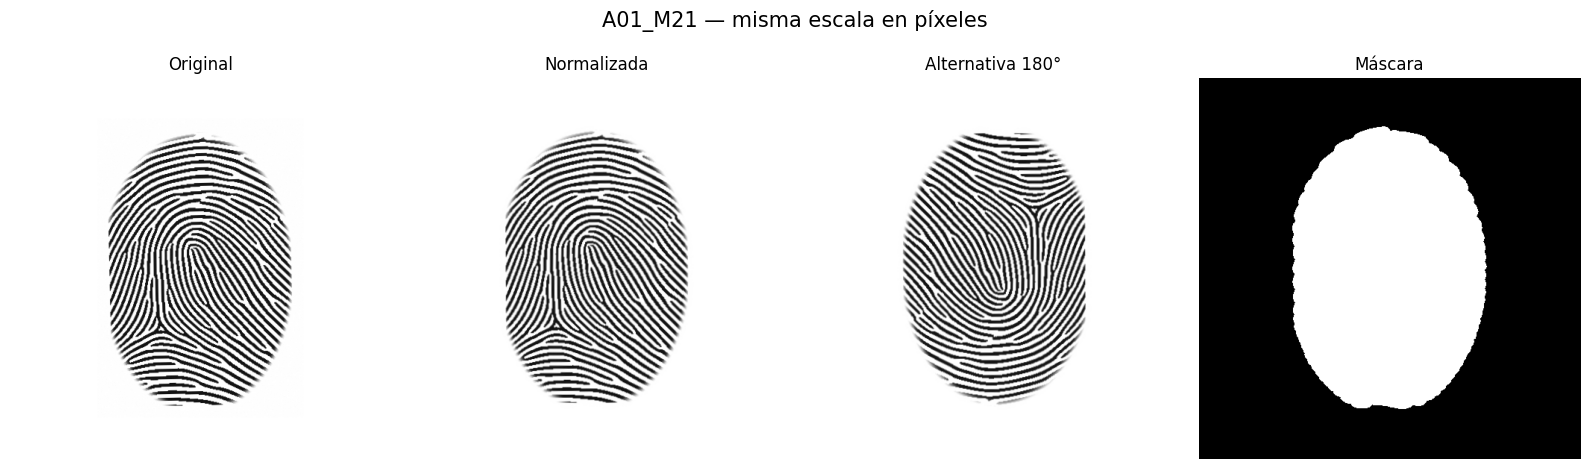

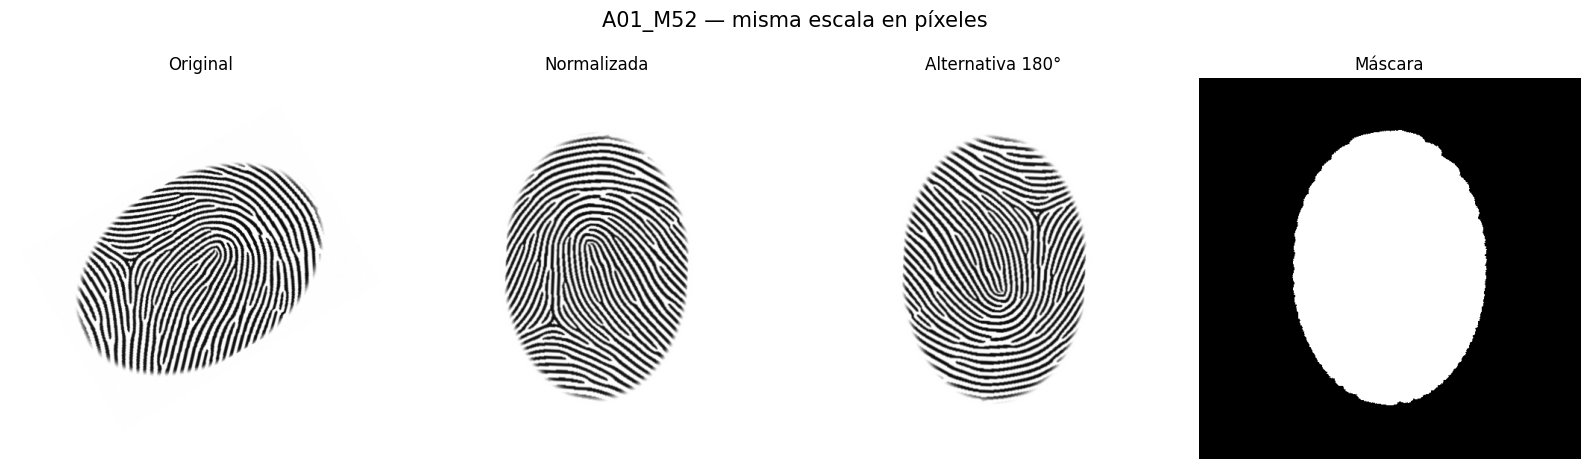

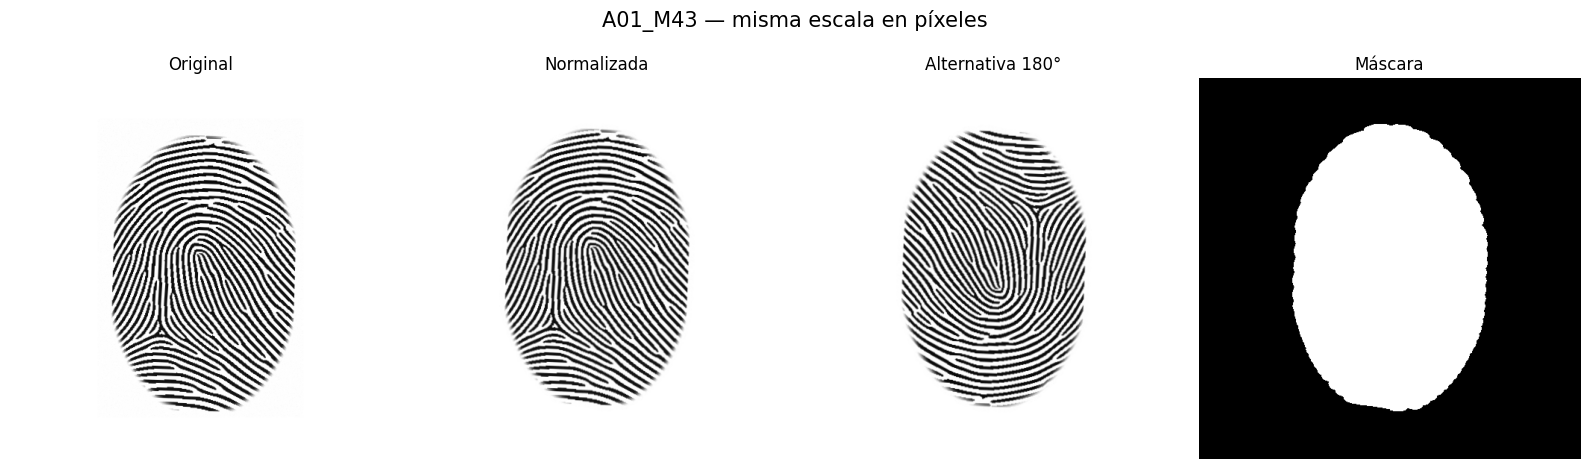

In [4]:
seleccion = ["A01_M21", "A01_M52", "A01_M43"]
for nombre in seleccion:
    r = next(r for r in filas if r["muestra"] == nombre)
    assert r["particion"] in ["entrenamiento", "validacion"]
    principal = RAIZ / r["normalizada"]
    rutas = [RAIZ / r["original"], principal, RAIZ / r["alternativa_180"],
             principal.with_name(principal.stem + "_mascara.png")]
    fig, axs = plt.subplots(1, 4, figsize=(16, 5))
    for ax, ruta, titulo in zip(axs, rutas, ["Original", "Normalizada", "Alternativa 180°", "Máscara"]):
        with Image.open(ruta) as im:
            imagen = im.convert("L")
            lienzo = Image.new("L", (512, 512), 255)
            lienzo.paste(imagen, ((512-imagen.width)//2, (512-imagen.height)//2))
            ax.imshow(lienzo, cmap="gray", vmin=0, vmax=255)
        ax.set_title(titulo); ax.axis("off")
    fig.suptitle(f"{nombre} — misma escala en píxeles", fontsize=15)
    plt.tight_layout(); plt.show()

In [5]:
detalle = json.loads((SALIDA / "detalle.json").read_text(encoding="utf-8"))
print("Avisos de desarrollo:")
for registro in detalle:
    if registro["particion"] != "prueba" and registro.get("avisos"):
        print(registro["muestra"], ":", "; ".join(registro["avisos"]))
print("No usar los casos de prueba para ajustar el método ni seleccionar parámetros.")

Avisos de desarrollo:
A01_M43 : La región alcanza un borde de la entrada: posible recorte previo.
A02_M44 : La región alcanza un borde de la entrada: posible recorte previo.
No usar los casos de prueba para ajustar el método ni seleccionar parámetros.


## 11. Interpretación de los controles y cierre de etapa

En la ejecución publicada, cuyo resumen y controles se muestran arriba, se procesaron 220 muestras: **218 sin avisos, 2 para revisar y 0 errores**. Los avisos de A01_M43 y A02_M44 señalan que la región llega a un borde del original. Esto puede indicar contacto parcial o un recorte previo; no implica que el programa haya fallado ni justifica descartar automáticamente la muestra.

La salida de las celdas anteriores documenta las comprobaciones de esta ejecución. La inspección visual complementaria debe considerar posibles recortes nuevos, estiramientos y pérdida de crestas. Los controles de conteo y hashes no sustituyen ese análisis.

**Cierre de alcance:** quedan implementadas la generación sintética y la normalización geométrica v1. El contraste, la resolución física y la dirección anatómica única no se han normalizado. No se han medido tasas de acierto o de falsa aceptación.

El módulo de huellas deberá continuar con la representación de características, K-means con k = 3 y un umbral de aceptación/rechazo. La comparación deberá contemplar la alternativa de 180°. En paralelo, el proyecto requiere un dataset de comandos de voz y su clasificación mediante K-NN. La evaluación deberá reconocer la limitada diversidad de bases y respetar la reserva de prueba.

La consigna también contempla acondicionamiento de contraste y filtrado para resaltar la estructura de las huellas. Esas decisiones permanecen pendientes de la selección y validación de características. Por tanto, el cierre corresponde a la **normalización geométrica v1**, no a todo el preprocesamiento ni al sistema completo.

## 12. Qué reutilizar a partir de ahora

- **Índice de muestras:** `datos/procesados/normalizacion_final_v1/catalogo_normalizado.csv`.
- **Entrada del futuro reconocedor:** las rutas `normalizada` y `alternativa_180`, conservando una sola fila por muestra.
- **Región de análisis:** la máscara, cuando el método de características la necesite.
- **Nuevas capturas:** llamar a `normalizar_huella` de `src/normalizacion_final.py`, con la misma configuración del lote.
- **Trazabilidad:** conservar bases, originales, configuraciones, catálogos y código.

Ejemplo para un programa ubicado en `src/` (referencia; no se ejecuta aquí):

```python
import json
from pathlib import Path
from PIL import Image
from normalizacion_final import normalizar_huella

raiz = Path(__file__).resolve().parents[1]
cfg = json.loads((raiz / 'config/roi_normalizacion_v1.json').read_text(encoding='utf-8-sig'))
with Image.open(ruta_de_entrada) as imagen:
    principal, info = normalizar_huella(imagen, cfg)
alternativa = info['alternativa_180']
mascara = info['mascara_normalizada']
# Revisar info['avisos'] y manejar ValueError antes de continuar.
```

Para reconstruir desde las bases, los programas se ejecutan en este orden: `generar_conjunto.py`, `ampliar_entrenamiento.py`, `ampliar_rotaciones.py`, `normalizar_todas.py`. Esta reconstrucción requiere una copia de trabajo sin catálogos ni salidas generadas; los programas protegen las salidas existentes. El notebook es una explicación y comprobación, no un segundo generador.

## 13. Continuidad y uso de IA generativa

Esta bitácora conserva el alcance y los resultados de la primera etapa de huellas. Los avances posteriores se registrarán en notebooks nuevos y en la tabla de etapas del README. La bitácora es documentación de desarrollo; el informe final en PDF solicitado por la cátedra se elaborará integrando las etapas y su evaluación.

Se utilizó ChatGPT como apoyo en la generación y revisión de código, documentación y comprobaciones. Los patrones base proceden de Anguli. El [registro de uso de IA generativa](../documentos/uso_ia_generativa.md) describe las tareas asistidas, ejemplos de solicitudes y la verificación realizada. Las referencias técnicas y las pruebas auxiliares se conservan en los documentos históricos identificados en el [índice de documentación](../documentos/README.md).
